<a href="https://colab.research.google.com/github/leonie31212/Business-Analytics/blob/main/Skiresorts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###**Datengrundlage hinzufügen und lesen.**

In [20]:
import pandas as pd
import io

# Da die gesamte Zeile in Anführungszeichen eingeschlossen ist, bereinigen wir die Datei beim Einlesen.
with open('/content/European_Ski_Resorts.csv', 'r', encoding='utf-8') as f:
    lines = f.readlines()

# Bereinige die Zeilen von den äußeren Anführungszeichen und korrigiere doppelte Anführungszeichen
cleaned_lines = []
for line in lines:
    line = line.strip()
    if line.startswith('"') and line.endswith('"'):
        line = line[1:-1] # Entferne äußere Anführungszeichen
    line = line.replace('""', '"') # Ersetze doppelte Anführungszeichen durch einfache
    cleaned_lines.append(line)

# In ein DataFrame laden
df = pd.read_csv(io.StringIO('\n'.join(cleaned_lines)), index_col=0)

# Die ersten Zeilen des bereinigten Datensatzes anzeigen
df.head()

,Resort,Country,HighestPoint,LowestPoint,DayPassPriceAdult,BeginnerSlope,IntermediateSlope,DifficultSlope,TotalSlope,Snowparks,NightSki,SurfaceLifts,ChairLifts,GondolaLifts,TotalLifts,LiftCapacity,SnowCannons
1,Alpendorf (Ski amedé),Austria,1980,740,52,30,81,4,115,Yes,No,22,16,11,49,75398,600
2,Soldeu-Pas de la Casa/​Grau Roig/​El Tarter/​C...,Andorra,2640,1710,47,100,77,33,210,Yes,Yes,37,28,7,72,99017,1032
3,Oberau (Wildschönau),Austria,1130,900,30,1,0,1,2,No,No,2,0,0,2,1932,0
4,Dachstein West,Austria,1620,780,42,15,33,3,51,Yes,Yes,25,8,3,36,32938,163
5,Rosa Khutor,Southern Russia,2320,940,22,30,26,21,77,Yes,No,6,11,10,27,49228,450


###**Größe und Typ der Skigebiete definieren.**

In [21]:
import numpy as np

# 1. Definition der Größe (dreigeteilt: klein, mittel, groß) basierend auf der Gesamtpistenlänge (TotalSlope)
# Wir nutzen Quantile (33% und 66%), um eine gleichmäßige Dreiteilung zu erzielen
low_threshold = df['TotalSlope'].quantile(0.33)
high_threshold = df['TotalSlope'].quantile(0.66)

def categorize_size(slope):
    if slope <= low_threshold:
        return 'klein'
    elif slope <= high_threshold:
        return 'mittel'
    else:
        return 'groß'

df['Groessenklasse'] = df['TotalSlope'].apply(categorize_size)

# 2. Definition des Typs der Skigebiete basierend auf der Verteilung der Pistenarten (Anfänger vs. Fortgeschrittene/Profis)
def define_resort_type(row):
    total = row['TotalSlope']
    if total == 0:
        return 'Nicht spezifiziert'

    beginner_ratio = row['BeginnerSlope'] / total
    difficult_ratio = row['DifficultSlope'] / total

    if beginner_ratio > 0.5:
        return 'Anfängerfreundlich'
    elif difficult_ratio > 0.25:
        return 'Anspruchsvoll / Profis'
    else:
        return 'Ausgewogen / Allrounder'

df['ResortTyp'] = df.apply(define_resort_type, axis=1)

# Ergebnisse anzeigen
print(f"Größen-Schwellenwerte: Klein <= {low_threshold:.1f} km, Mittel <= {high_threshold:.1f} km, Groß > {high_threshold:.1f} km\n")
display(df[['Resort', 'TotalSlope', 'Groessenklasse', 'ResortTyp']].head(10))

# Verteilung anzeigen
print("\nVerteilung der Größenklassen:")
print(df['Groessenklasse'].value_counts())
print("\nVerteilung der Resort-Typen:")
print(df['ResortTyp'].value_counts())

Größen-Schwellenwerte: Klein <= 32.0 km, Mittel <= 68.5 km, Groß > 68.5 km



,Resort,TotalSlope,Groessenklasse,ResortTyp
1,Alpendorf (Ski amedé),115,groß,Ausgewogen / Allrounder
2,Soldeu-Pas de la Casa/​Grau Roig/​El Tarter/​C...,210,groß,Ausgewogen / Allrounder
3,Oberau (Wildschönau),2,klein,Anspruchsvoll / Profis
4,Dachstein West,51,mittel,Ausgewogen / Allrounder
5,Rosa Khutor,77,groß,Anspruchsvoll / Profis
6,Białka Tatrzańska-Kotelnica-​Kaniówka-​Bania,16,klein,Anfängerfreundlich
7,Vitosha-Sofia,20,klein,Anfängerfreundlich
8,Szczyrk-Skrzyczne,35,mittel,Anfängerfreundlich
9,Jahorina,25,klein,Ausgewogen / Allrounder
10,Kobla-Bohinj,23,klein,Anfängerfreundlich



Verteilung der Größenklassen:
Groessenklasse
groß      128
klein     125
mittel    123
Name: count, dtype: int64

Verteilung der Resort-Typen:
ResortTyp
Ausgewogen / Allrounder    235
Anfängerfreundlich         101
Anspruchsvoll / Profis      29
Nicht spezifiziert          11
Name: count, dtype: int64


###**Zeilen mit Typ "Nicht spezifiziert" löschen.**

In [22]:
# Zeilen löschen, bei denen der ResortTyp 'Nicht spezifiziert' ist
df_filtered = df[df['ResortTyp'] != 'Nicht spezifiziert']

# Bestätigung und neue Form anzeigen
print(f"Ursprüngliche Zeilenanzahl: {len(df)}")
print(f"Neue Zeilenanzahl nach dem Löschen: {len(df_filtered)}")
print(f"Gelöschte Zeilen: {len(df) - len(df_filtered)}")

# Das gefilterte DataFrame wieder als Standard df setzen
df = df_filtered

# Aktualisierte Verteilung der Typen anzeigen
print("\nAktualisierte Verteilung der Resort-Typen:")
print(df['ResortTyp'].value_counts())

Ursprüngliche Zeilenanzahl: 376
Neue Zeilenanzahl nach dem Löschen: 365
Gelöschte Zeilen: 11

Aktualisierte Verteilung der Resort-Typen:
ResortTyp
Ausgewogen / Allrounder    235
Anfängerfreundlich         101
Anspruchsvoll / Profis      29
Name: count, dtype: int64


### **Zeilen mit Tagespass-Preis = 0 löschen.**

In [23]:
# Zeilen löschen, bei denen der Tagespass-Preis (DayPassPriceAdult) gleich 0 ist
df_filtered_price = df[df['DayPassPriceAdult'] > 0]

print(f"Anzahl der Skigebiete vorher: {len(df)}")
print(f"Anzahl der Skigebiete nach dem Filtern (Preis > 0 €): {len(df_filtered_price)}")
print(f"Entfernte Gebiete mit 0 € Preis: {len(df) - len(df_filtered_price)}")

# Haupt-DataFrame aktualisieren
df = df_filtered_price

Anzahl der Skigebiete vorher: 365
Anzahl der Skigebiete nach dem Filtern (Preis > 0 €): 361
Entfernte Gebiete mit 0 € Preis: 4


###**Frage 1: Sind große Skigebiete pro Kilometer günstiger?**

Wir berechnen den Preis pro Kilometer für jedes Skigebiet (`DayPassPriceAdult` / `TotalSlope`) und vergleichen den Durchschnitt dieses Wertes über die verschiedenen Größenklassen (`Groessenklasse`).

,Anzahl,Durchschnittlicher_Passpreis,Durchschnittliche_Pistenlaenge,Durchschnitt_Preis_pro_Km,Median_Preis_pro_Km
Groessenklasse,,,,,
klein,111,35.108108,17.072072,4.082871,2.000000
mittel,122,40.540984,47.631148,0.878684,0.866667
groß,128,48.960938,192.320312,0.352094,0.329545


/tmp/ipykernel_1257/2951106763.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=summary.index, y='Durchschnitt_Preis_pro_Km', data=summary, palette='Blues_d')


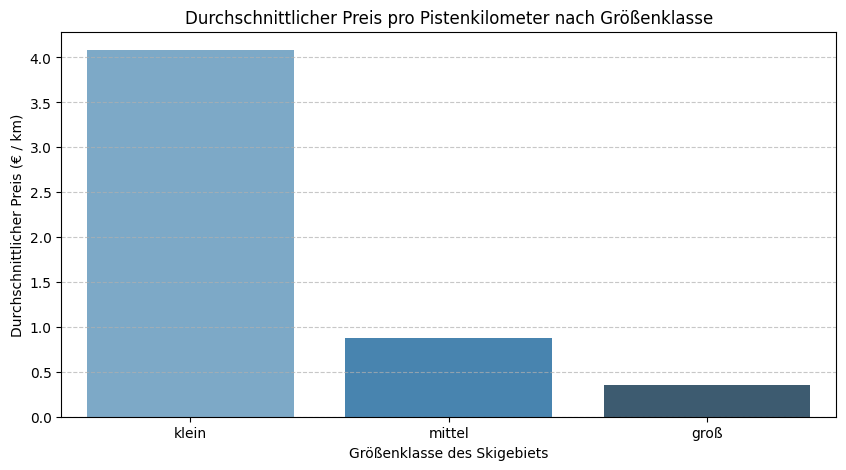

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Berechnung des Preises pro Kilometer (nur für Gebiete mit Pistenlänge > 0, um Division durch Null zu vermeiden)
df_price_analysis = df[df['TotalSlope'] > 0].copy()
df_price_analysis['PricePerKm'] = df_price_analysis['DayPassPriceAdult'] / df_price_analysis['TotalSlope']

# Aggregierte Auswertung nach Größenklasse
summary = df_price_analysis.groupby('Groessenklasse').agg(
    Anzahl=('Resort', 'count'),
    Durchschnittlicher_Passpreis=('DayPassPriceAdult', 'mean'),
    Durchschnittliche_Pistenlaenge=('TotalSlope', 'mean'),
    Durchschnitt_Preis_pro_Km=('PricePerKm', 'mean'),
    Median_Preis_pro_Km=('PricePerKm', 'median')
).reindex(['klein', 'mittel', 'groß'])

display(summary)

# Visualisierung
plt.figure(figsize=(10, 5))
sns.barplot(x=summary.index, y='Durchschnitt_Preis_pro_Km', data=summary, palette='Blues_d')
plt.title('Durchschnittlicher Preis pro Pistenkilometer nach Größenklasse')
plt.xlabel('Größenklasse des Skigebiets')
plt.ylabel('Durchschnittlicher Preis (€ / km)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

###**Frage 2: Preisvergleich zwischen Österreich, Frankreich, der Schweiz und Italien nach Größenklasse**

Wir filtern die Skigebiete für die vier gefragten Länder und vergleichen die durchschnittlichen Preise der Tageskarte (`DayPassPriceAdult`) innerhalb der jeweiligen Größenklassen.

,Groessenklasse,Country,mean,count
5,klein,France,34.636364,11
6,klein,Italy,35.333333,6
4,klein,Austria,38.187500,32
7,klein,Switzerland,47.818182,11
9,mittel,France,31.923077,26
10,mittel,Italy,42.100000,20
8,mittel,Austria,43.708333,24
11,mittel,Switzerland,48.000000,26
1,groß,France,43.909091,44
2,groß,Italy,45.705882,17


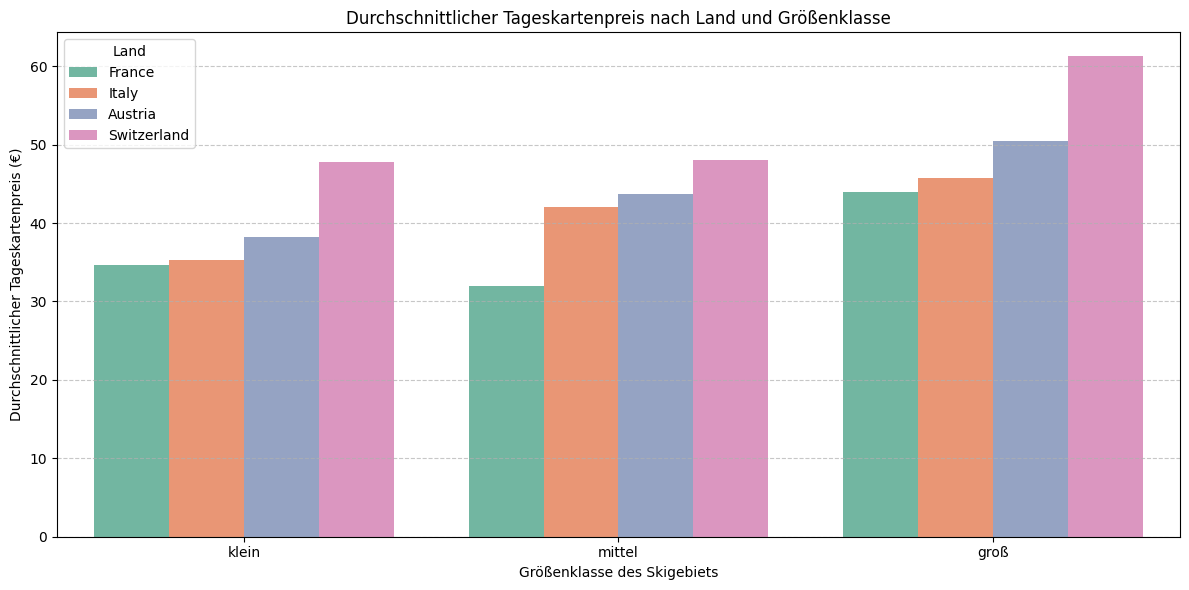

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Liste der Zielländer
countries = ['Austria', 'France', 'Switzerland', 'Italy']

# Daten filtern
df_countries = df[df['Country'].isin(countries)].copy()

# Aggregation: Durchschnittlicher Preis nach Land und Größenklasse
price_comparison = df_countries.groupby(['Groessenklasse', 'Country'])['DayPassPriceAdult'].agg(['mean', 'count']).reset_index()
# Sortierung der Größenklasse für eine logische Reihenfolge im Plot
price_comparison['Groessenklasse'] = pd.Categorical(price_comparison['Groessenklasse'], categories=['klein', 'mittel', 'groß'], ordered=True)
price_comparison = price_comparison.sort_values(['Groessenklasse', 'mean'])

display(price_comparison)

# Visualisierung erstellen
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Groessenklasse',
    y='mean',
    hue='Country',
    data=price_comparison,
    palette='Set2'
)

plt.title('Durchschnittlicher Tageskartenpreis nach Land und Größenklasse')
plt.xlabel('Größenklasse des Skigebiets')
plt.ylabel('Durchschnittlicher Tageskartenpreis (€)')
plt.legend(title='Land')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

###**Frage 3: Welche Variablen erklären den Tagespreis am besten?**

Wir berechnen neue Features wie **Höhendifferenz** und den **Anteil schwerer Pisten** und führen eine Feature-Importance-Analyse mithilfe eines Random Forest Regressors durch, um den Einfluss der Variablen (Pistenkilometer, Höhenlage, Höhendifferenz, Anteil schwerer Pisten und Land) zu vergleichen.

Erklärte Varianz (R² des Modells auf den Trainingsdaten): 0.96



,Variable,Wichtigkeit
2,Höhendifferenz (HeightDifference),0.282767
0,Pistenkilometer (TotalSlope),0.265080
4,Land (Kombinierter Effekt aller Länder),0.262504
1,Höhenlage (HighestPoint),0.130525
3,Anteil schwerer Pisten (DifficultSlopeRatio),0.059124


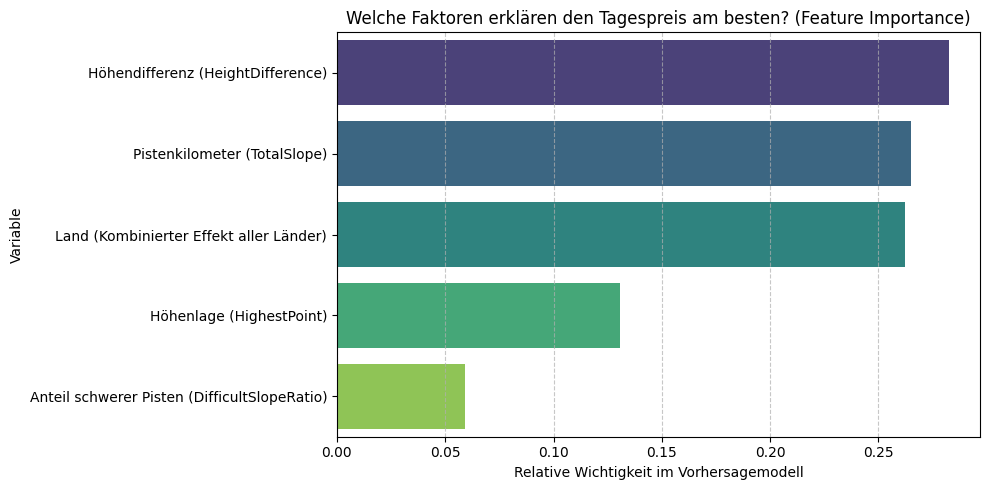

In [27]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns

# Datensatz für die Modellierung vorbereiten
df_model = df.copy()

# 1. Feature-Engineering
df_model['HeightDifference'] = df_model['HighestPoint'] - df_model['LowestPoint']
df_model['DifficultSlopeRatio'] = df_model['DifficultSlope'] / df_model['TotalSlope'].replace(0, np.nan)
df_model['DifficultSlopeRatio'] = df_model['DifficultSlopeRatio'].fillna(0)

# Zielvariable und Features definieren
# Wir nutzen die vom Nutzer genannten Variablen
features = ['TotalSlope', 'HighestPoint', 'HeightDifference', 'DifficultSlopeRatio', 'Country']
target = 'DayPassPriceAdult'

# Zeilen mit fehlenden Werten im Ziel oder in den Features ausschließen
df_model = df_model.dropna(subset=[target] + features[:-1])

X = df_model[features]
y = df_model[target]

# Kategoriale Variablen (Country) transformieren und Random Forest trainieren
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', ['TotalSlope', 'HighestPoint', 'HeightDifference', 'DifficultSlopeRatio']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Country'])
    ]
)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Modell fitten, um R² zu ermitteln
model.fit(X, y)
r2_score = model.score(X, y)
print(f"Erklärte Varianz (R² des Modells auf den Trainingsdaten): {r2_score:.2f}\n")

# Feature-Importances extrahieren
# Namen der Features nach dem One-Hot-Encoding holen
ohe_categories = model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(['Country'])
feature_names = ['TotalSlope', 'HighestPoint', 'HeightDifference', 'DifficultSlopeRatio'] + list(ohe_categories)
importances = model.named_steps['regressor'].feature_importances_

# Da das Land in viele Einzel-Länder aufgeteilt wurde, fassen wir die Wichtigkeit des Lands als Gruppe zusammen
base_features_importances = {
    'Pistenkilometer (TotalSlope)': importances[0],
    'Höhenlage (HighestPoint)': importances[1],
    'Höhendifferenz (HeightDifference)': importances[2],
    'Anteil schwerer Pisten (DifficultSlopeRatio)': importances[3],
    'Land (Kombinierter Effekt aller Länder)': sum(importances[4:])
}

# DataFrame erstellen und sortieren
importance_df = pd.DataFrame(list(base_features_importances.items()), columns=['Variable', 'Wichtigkeit']).sort_values(by='Wichtigkeit', ascending=False)

display(importance_df)

# Visualisierung
plt.figure(figsize=(10, 5))
sns.barplot(x='Wichtigkeit', y='Variable', data=importance_df, palette='viridis', hue='Variable', legend=False)
plt.title('Welche Faktoren erklären den Tagespreis am besten? (Feature Importance)')
plt.xlabel('Relative Wichtigkeit im Vorhersagemodell')
plt.ylabel('Variable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### **Frage 4: Welche Typen von Skigebieten gibt es, und welche Gebiete sind für ihren Typ auffällig günstig oder teuer?**

Wir nutzen die zuvor definierten **Resort-Typen** (*Anfängerfreundlich*, *Anspruchsvoll / Profis* und *Ausgewogen / Allrounder*) und analysieren die Verteilung der Tageskartenpreise innerhalb dieser Gruppen anhand der bereinigten Daten.

Um auffällige Preisausreißer zu identifizieren:
1. Berechnen wir den **Median-Preis** für jeden Skigebietstyp.
2. Bestimmen wir die Abweichung jedes Skigebiets vom Median seines Typs.
3. Identifizieren wir die extremsten Ausreißer (die jeweils 2 teuersten und günstigsten Skigebiete pro Typ) und visualisieren diese mithilfe eines **Boxplots**.

Median-Tageskartenpreise nach Skigebietstyp (ohne 0-€-Einträge):
 - Anfängerfreundlich: 41.0 €
 - Anspruchsvoll / Profis: 42.5 €
 - Ausgewogen / Allrounder: 43.0 €


,Resort,Country,DayPassPriceAdult,PriceDiff,ResortTyp,Kategorie
16,Méribel (Les 3 Vallées),France,61,20.0,Anfängerfreundlich,Auffällig Teuer
17,​Les Menuires (Les 3 Vallées),France,61,20.0,Anfängerfreundlich,Auffällig Teuer
7,Vitosha-Sofia,Bulgaria,18,-23.0,Anfängerfreundlich,Auffällig Günstig
242,Jochgrimm-Passo Oclini-,Italy,17,-24.0,Anfängerfreundlich,Auffällig Günstig
297,Grands Montets-Argentière (Chamonix),France,62,19.5,Anspruchsvoll / Profis,Auffällig Teuer
245,Diavolezza-​Lagalb,Switzerland,59,16.5,Anspruchsvoll / Profis,Auffällig Teuer
239,Götschen-Bischofswiesen,Germany,25,-17.5,Anspruchsvoll / Profis,Auffällig Günstig
5,Rosa Khutor,Southern Russia,22,-20.5,Anspruchsvoll / Profis,Auffällig Günstig
296,Cervinia,Switzerland,81,38.0,Ausgewogen / Allrounder,Auffällig Teuer
336,Zermatt - Matterhorn,Switzerland,81,38.0,Ausgewogen / Allrounder,Auffällig Teuer


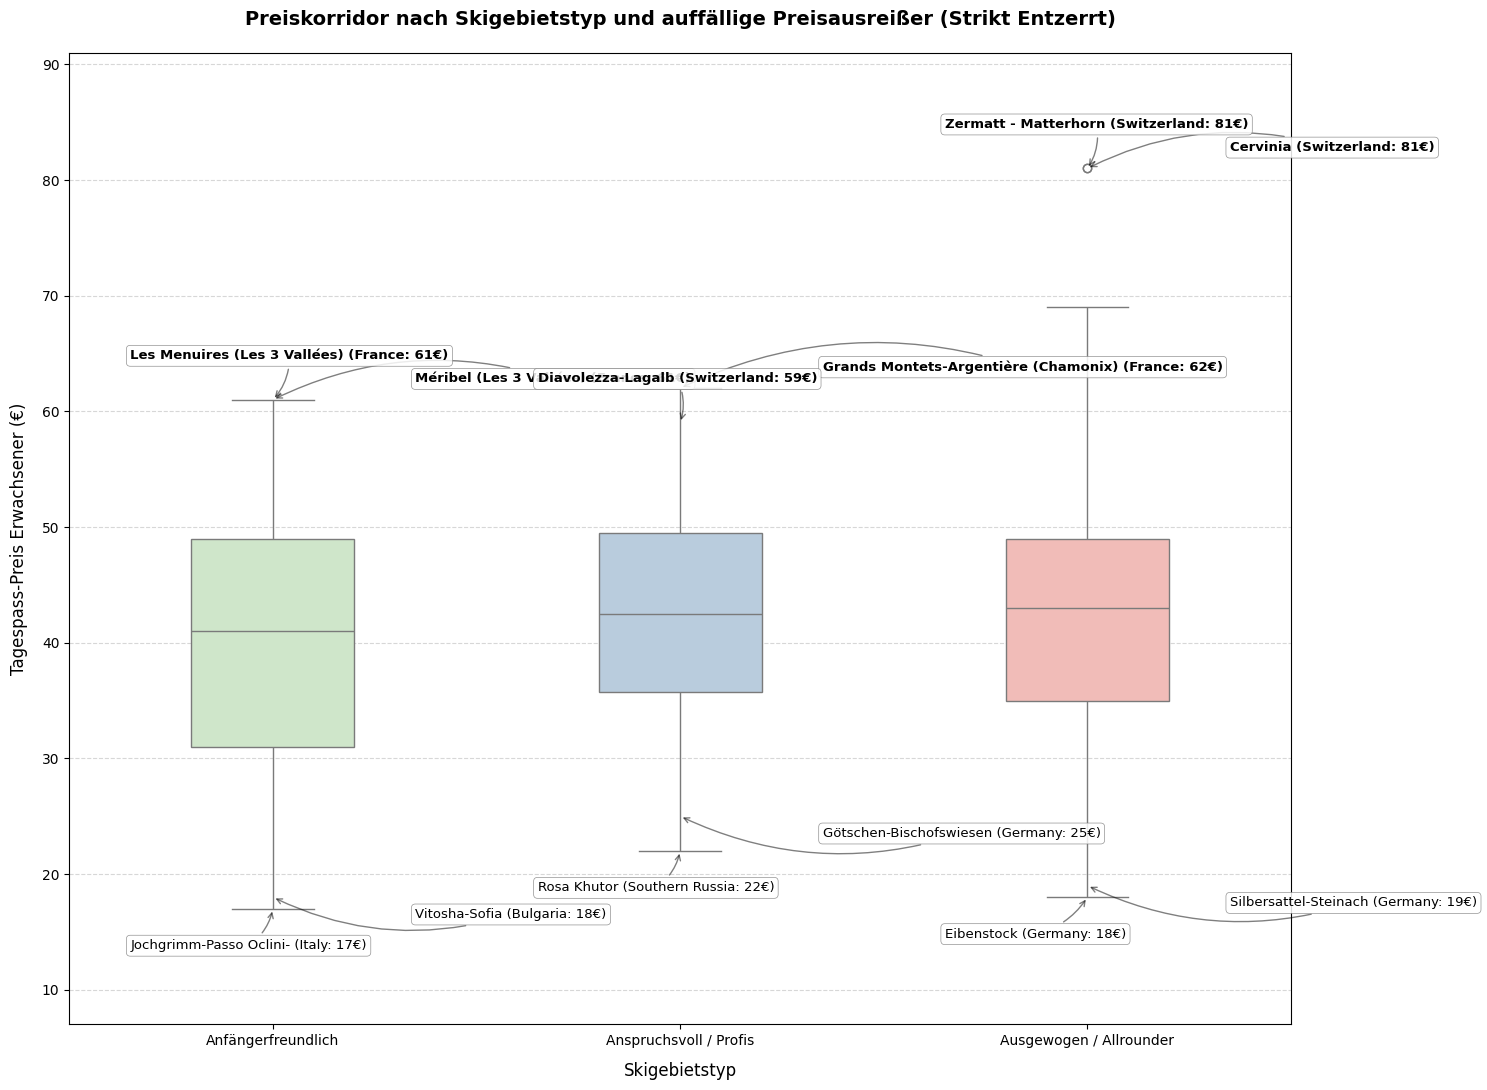

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Median-Preis pro Skigebietstyp berechnen
type_medians = df.groupby('ResortTyp')['DayPassPriceAdult'].median().to_dict()
print("Median-Tageskartenpreise nach Skigebietstyp (ohne 0-€-Einträge):")
for r_type, median in type_medians.items():
    print(f" - {r_type}: {median:.1f} €")

# 2. Differenz zum Typen-Median für jedes Skigebiet ermitteln
df_outliers = df.copy()
df_outliers['TypeMedian'] = df_outliers['ResortTyp'].map(type_medians)
df_outliers['PriceDiff'] = df_outliers['DayPassPriceAdult'] - df_outliers['TypeMedian']

# 3. Die jeweils 2 am stärksten nach oben und unten abweichenden Gebiete pro Typ filtern
outliers_list = []
for r_type in type_medians.keys():
    df_sub = df_outliers[df_outliers['ResortTyp'] == r_type]

    # Die 2 am stärksten über dem Median liegenden Gebiete
    teuer = df_sub.nlargest(2, 'PriceDiff')[['Resort', 'Country', 'DayPassPriceAdult', 'PriceDiff', 'ResortTyp']]
    teuer['Kategorie'] = 'Auffällig Teuer'

    # Die 2 am stärksten unter dem Median liegenden Gebiete
    guenstig = df_sub.nsmallest(2, 'PriceDiff')[['Resort', 'Country', 'DayPassPriceAdult', 'PriceDiff', 'ResortTyp']]
    guenstig['Kategorie'] = 'Auffällig Günstig'

    outliers_list.extend([teuer, guenstig])

df_outliers_report = pd.concat(outliers_list).sort_values(by=['ResortTyp', 'PriceDiff'], ascending=[True, False])
display(df_outliers_report)

# 4. Boxplot erstellen mit expliziter Reihenfolge für verlässliche X-Koordinaten
plt.figure(figsize=(15, 11))

# Wir legen die Reihenfolge der X-Achse explizit fest
plot_order = ['Anfängerfreundlich', 'Anspruchsvoll / Profis', 'Ausgewogen / Allrounder']
sns.boxplot(x='ResortTyp', y='DayPassPriceAdult', data=df_outliers, order=plot_order, palette='Pastel1', hue='ResortTyp', legend=False, width=0.4)

# Um Überlappungen vollständig zu vermeiden, fächern wir die Paare extrem strikt nach links und rechts auf
used_positions = {}

for idx, row in df_outliers_report.iterrows():
    resort_name = row['Resort']
    y_val = row['DayPassPriceAdult']
    x_val = plot_order.index(row['ResortTyp'])  # Exakte Position auf der X-Achse

    is_teuer = row['Kategorie'] == 'Auffällig Teuer'
    pos_key = (x_val, row['Kategorie'])

    if pos_key in used_positions:
        # Zweites Element der Gruppe -> wandert immer nach links
        x_offset = -0.35
        y_offset = 3.5 if is_teuer else -3.5
        rad_val = -0.2 if is_teuer else 0.2
    else:
        # Erstes Element der Gruppe -> wandert immer nach rechts
        x_offset = 0.35
        y_offset = 1.5 if is_teuer else -1.8
        rad_val = 0.2 if is_teuer else -0.2
        used_positions[pos_key] = True

    plt.annotate(f"{resort_name} ({row['Country']}: {y_val}€)",
                 xy=(x_val, y_val),
                 xytext=(x_val + x_offset, y_val + y_offset),
                 arrowprops=dict(facecolor='black', arrowstyle='->', alpha=0.5, connectionstyle=f"arc3,rad={rad_val}"),
                 fontsize=9.5,
                 fontweight='semibold' if is_teuer else 'normal',
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.5, alpha=0.85))

plt.title('Preiskorridor nach Skigebietstyp und auffällige Preisausreißer (Strikt Entzerrt)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Skigebietstyp', fontsize=12, labelpad=10)
plt.ylabel('Tagespass-Preis Erwachsener (€)', fontsize=12, labelpad=10)
plt.ylim(df_outliers['DayPassPriceAdult'].min() - 10, df_outliers['DayPassPriceAdult'].max() + 10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()